# Quadruped Leg — Kinematics, Dynamics and Simulation

Model of the **front-right leg of a Unitree Go2–style quadruped** with the body welded in place (no floating base):

1. Closed-form **forward kinematics** of the foot.
2. A **URDF model** of the body and the leg built from primitive shapes.
3. **Verification** of the kinematics with [Pinocchio](https://github.com/stack-of-tasks/pinocchio).
4. The foot **Jacobian**, checked with $\mathbf V = \mathbf J\dot{\mathbf q}$ and with finite differences.
5. An **Euler–Lagrange model** of the thigh–calf chain, checked against Pinocchio's rigid-body algorithms.
6. **Simulation in [Drake](https://drake.mit.edu)**: passive fall, gravity compensation, and PD vs. PD + gravity-compensation position control.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # make the leg_model package importable

import numpy as np
import matplotlib.pyplot as plt
import pinocchio as pin
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image

from leg_model import URDF_PATH, FOOT_FRAME
from leg_model.kinematics import forward_kinematics, joint_positions
from leg_model import planar_dynamics as pdm
from leg_model.simulation import LegSimulation

MEDIA = pathlib.Path.cwd().parent / "media"
rng = np.random.default_rng(42)

## 1. Leg geometry and conventions

| Joint | Axis (base frame) | Motion |
|---|---|---|
| `FR_hip_joint` $q_1$ | $x$ | abduction / adduction |
| `FR_thigh_joint` $q_2$ | $y$ | hip flexion / extension |
| `FR_calf_joint` $q_3$ | $y$ (relative to the thigh) | knee flexion / extension |

At $\mathbf q = \mathbf 0$ the leg is fully stretched along the $-z$ axis of the body.

| Quantity | Value |
|---|---|
| hip joint in body frame | $(0.1934,\ -0.0465,\ 0)$ m |
| hip → thigh lateral offset $d$ | 0.0955 m |
| thigh length $l_1$, calf length $l_2$ | 0.213 m each |
| body height above ground | 0.5 m |

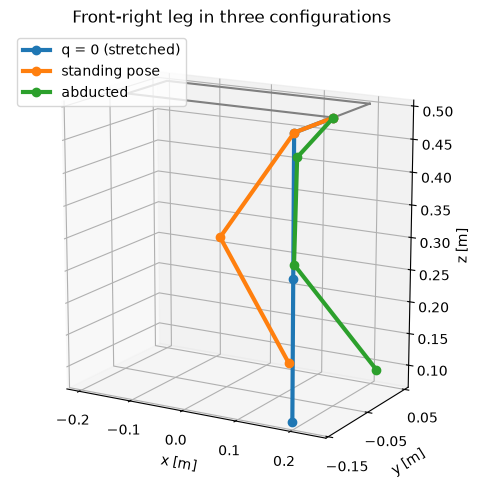

In [2]:
def draw_leg(ax, q, **kw):
    P = joint_positions(q)
    ax.plot(P[1:, 0], P[1:, 1], P[1:, 2], "o-", lw=3, **kw)

fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(projection="3d")
# Body outline
bx, by = 0.3868 / 2, 0.093 / 2
corners = np.array([[bx, by], [bx, -by], [-bx, -by], [-bx, by], [bx, by]])
ax.plot(corners[:, 0], corners[:, 1], 0.5, color="gray")
for q, c, lab in [([0, 0, 0], "tab:blue", "q = 0 (stretched)"),
                  ([0, 0.67, -1.3], "tab:orange", "standing pose"),
                  ([0.4, 0.3, -0.8], "tab:green", "abducted")]:
    draw_leg(ax, np.array(q), color=c, label=lab)
ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]"); ax.set_zlabel("z [m]")
ax.set_yticks([-0.15, -0.05, 0.05]); ax.set_box_aspect((1, 0.6, 1)); ax.view_init(elev=15, azim=-60); ax.legend(loc="upper left")
ax.set_title("Front-right leg in three configurations")
fig.tight_layout(); fig.savefig(MEDIA / "leg_poses.png", dpi=120); plt.show()

## 2. Forward kinematics

The foot position follows from chaining one rotation per joint and adding the fixed offsets:

$$
\mathbf p_{foot} = \mathbf p_{hip}
+ \mathbf R_x(q_1)\begin{bmatrix}0\\-d\\0\end{bmatrix}
+ \mathbf R_x(q_1)\mathbf R_y(q_2)\begin{bmatrix}0\\0\\-l_1\end{bmatrix}
+ \mathbf R_x(q_1)\mathbf R_y(q_2+q_3)\begin{bmatrix}0\\0\\-l_2\end{bmatrix}
$$

Thigh and calf rotate about parallel axes, so the calf's absolute pitch is $q_2 + q_3$. Writing the sagittal reach as $a = l_1\sin q_2 + l_2\sin(q_2+q_3)$ and $b = l_1\cos q_2 + l_2\cos(q_2+q_3)$ gives

$$
\mathbf p_{foot} =
\begin{bmatrix}
0.1934 - a\\
-0.0465 - d\cos q_1 + b\sin q_1\\
h - d\sin q_1 - b\cos q_1
\end{bmatrix}
$$

with body height $h = 0.5$ m. The body is raised so that the leg does not collide with the ground plane in the simulation.

In [3]:
q_example = np.array([0.1, 0.3, 0.8])
print("foot position for q =", q_example, "->", forward_kinematics(q_example).round(4), "m")

foot position for q = [0.1 0.3 0.8] -> [-0.0594 -0.1116  0.1919] m


## 3. URDF model

[`urdf/front_right_leg.urdf`](../urdf/front_right_leg.urdf) contains:

- `world → body`: fixed joint at $z = 0.5$ m. The body is a box $0.3868 \times 0.093 \times 0.04$ m with a mass of 10 kg.
- `FR_hip` (cylinder, 0.25 kg), `FR_thigh` and `FR_calf` (cylinders $r = 0.02$ m, $l = 0.213$ m, 0.5 kg each), and a fixed `FR_foot` sphere (0.1 kg).
- One `transmission` per actuated joint, which Drake needs to create the actuators.

The masses are rough estimates: a Go2 weighs about 15 kg, and most of that is in the body. Inertias use the solid-body formulas about each centre of mass:

$$
I_{box} = \tfrac{m}{12}\operatorname{diag}(b^2+c^2,\ a^2+c^2,\ a^2+b^2),\quad
I_{cyl} = \operatorname{diag}\!\big(\tfrac{m}{12}(3r^2+l^2),\ \tfrac{m}{12}(3r^2+l^2),\ \tfrac{m}{2}r^2\big),\quad
I_{sphere} = \tfrac{2}{5}mr^2\,\mathbf 1
$$

The next cell checks that the inertias in the URDF agree with these formulas.

In [4]:
model = pin.buildModelFromUrdf(URDF_PATH)
data = model.createData()
foot_id = model.getFrameId(FOOT_FRAME)
print(model)

def cyl(m, r, l):
    t = m / 12 * (3 * r**2 + l**2)
    return np.array([t, t, m * r**2 / 2])

# Pinocchio merges the fixed foot sphere into the calf body, so check hip and thigh
expected = {"FR_hip_joint": cyl(0.25, 0.02, 0.0955)[[0, 2, 1]],     # hip cylinder lies along y
            "FR_thigh_joint": cyl(0.5, 0.02, 0.213)}
for name, I_exp in expected.items():
    I_urdf = np.diag(model.inertias[model.getJointId(name)].inertia)
    print(f"{name:15s} URDF {I_urdf.round(6)}  formula {I_exp.round(6)}")
    assert np.allclose(I_urdf, I_exp, rtol=0.02)

Nb joints = 4 (nq=3,nv=3)
  Joint 0 universe: parent=0
  Joint 1 FR_hip_joint: parent=0
  Joint 2 FR_thigh_joint: parent=1
  Joint 3 FR_calf_joint: parent=2

FR_hip_joint    URDF [2.15e-04 5.00e-05 2.15e-04]  formula [2.15e-04 5.00e-05 2.15e-04]
FR_thigh_joint  URDF [0.00194 0.00194 0.0001 ]  formula [0.00194 0.00194 0.0001 ]


## 4. Verifying the forward kinematics with Pinocchio

`pin.framesForwardKinematics` gives the pose of every frame of the URDF model. The closed-form result must agree with it for **any** configuration, not only for one test point.

In [5]:
pin.framesForwardKinematics(model, data, q_example)
print("Pinocchio pose of FR_foot:\n", data.oMf[foot_id])

errors = []
for _ in range(1000):
    q = rng.uniform(-np.pi, np.pi, 3)
    pin.framesForwardKinematics(model, data, q)
    errors.append(np.linalg.norm(data.oMf[foot_id].translation - forward_kinematics(q)))
print(f"max |p_closed_form - p_pinocchio| over 1000 random configurations: {max(errors):.2e} m")
assert max(errors) < 1e-12

Pinocchio pose of FR_foot:
   R =
  0.453596          0   0.891207
 0.0889723   0.995004 -0.0452841
 -0.886755  0.0998334    0.45133
  p = -0.059373 -0.111563  0.191863

max |p_closed_form - p_pinocchio| over 1000 random configurations: 2.29e-16 m


## 5. Foot Jacobian

The frame Jacobian maps joint velocities to the spatial velocity of the foot, $\mathbf V = [\mathbf v;\ \boldsymbol\omega] = \mathbf J(\mathbf q)\,\dot{\mathbf q}$. Here it is expressed in the `LOCAL_WORLD_ALIGNED` frame: origin at the foot, axes parallel to the world.

Two independent checks:

1. $\mathbf J\dot{\mathbf q}$ equals the frame velocity that Pinocchio propagates through the kinematic tree.
2. The linear part $\mathbf J_v$ equals a central finite difference of the **closed-form** kinematics, $\mathbf J_v \approx \dfrac{\partial \mathbf p_{foot}}{\partial \mathbf q}$. This check does not use Pinocchio at all.

In [6]:
def jacobian(q):
    return pin.computeFrameJacobian(model, data, q, foot_id, pin.LOCAL_WORLD_ALIGNED)

def fd_jacobian(q, eps=1e-6):
    return np.column_stack([(forward_kinematics(q + eps * e) - forward_kinematics(q - eps * e)) / (2 * eps)
                            for e in np.eye(3)])

print("J(q_example) =\n", jacobian(q_example).round(4))

err_vel, err_fd = 0.0, 0.0
for _ in range(100):
    q, qd = rng.uniform(-np.pi, np.pi, 3), rng.uniform(-2, 2, 3)
    pin.forwardKinematics(model, data, q, qd)
    V = pin.getFrameVelocity(model, data, foot_id, pin.LOCAL_WORLD_ALIGNED).vector
    J = jacobian(q)
    err_vel = max(err_vel, np.abs(J @ qd - V).max())
    err_fd = max(err_fd, np.abs(J[:3] - fd_jacobian(q)).max())
print(f"max |J qd - V|            : {err_vel:.2e}")
print(f"max |J_v - finite diff.|  : {err_fd:.2e}")
assert err_vel < 1e-12 and err_fd < 1e-8

J(q_example) =
 [[ 0.     -0.3001 -0.0966]
 [ 0.3081 -0.0252 -0.019 ]
 [-0.0651  0.2515  0.1889]
 [ 1.      0.      0.    ]
 [ 0.      0.995   0.995 ]
 [ 0.      0.0998  0.0998]]
max |J qd - V|            : 4.44e-16
max |J_v - finite diff.|  : 9.80e-11


## 6. Euler–Lagrange model of the thigh–calf chain

With the hip held at $q_1 = 0$, thigh and calf move in the sagittal $x$–$z$ plane, like a planar two-link arm. Each link $i$ is a rigid body with mass $m_i$, centre of mass at distance $r_i$ from its joint, and inertia $I_i$ about the $y$-axis. The Lagrangian is

$$
L = \sum_i \Big(\tfrac12 m_i \|\dot{\mathbf p}_{c,i}\|^2 + \tfrac12 I_i\,\omega_i^2\Big) - \sum_i m_i g\, z_{c,i},
\qquad \omega_1 = \dot q_2,\ \ \omega_2 = \dot q_2 + \dot q_3
$$

SymPy derives $\mathbf M(\mathbf q)\ddot{\mathbf q} + \mathbf C(\mathbf q,\dot{\mathbf q}) + \mathbf G(\mathbf q) = \boldsymbol\tau$ (see [`leg_model/planar_dynamics.py`](../leg_model/planar_dynamics.py)):

In [7]:
import sympy as sp
for name, expr in [("M(q)", pdm.M_sym), ("C(q, dq)", pdm.C_sym), ("G(q)", pdm.G_sym)]:
    print(f"\n{name} ="); sp.pprint(expr)


M(q) =
⎡               2      ⎛  2                       2⎞       ⎛  2                ↪
⎢I₁ + I₂ + m₁⋅r₁  + m₂⋅⎝l₁  + 2⋅l₁⋅r₂⋅cos(q₃) + r₂ ⎠ + m_f⋅⎝l₁  + 2⋅l₁⋅l₂⋅cos( ↪
⎢                                                                              ↪
⎢                                                                              ↪
⎣                I₂ + l₂⋅m_f⋅(l₁⋅cos(q₃) + l₂) + m₂⋅r₂⋅(l₁⋅cos(q₃) + r₂)       ↪

↪         2⎞                                                         ⎤
↪ q₃) + l₂ ⎠  I₂ + l₂⋅m_f⋅(l₁⋅cos(q₃) + l₂) + m₂⋅r₂⋅(l₁⋅cos(q₃) + r₂)⎥
↪                                                                    ⎥
↪                                     2            2                 ⎥
↪                              I₂ + l₂ ⋅m_f + m₂⋅r₂                  ⎦

C(q, dq) =
⎡-dq₃⋅l₁⋅(2⋅dq₂⋅l₂⋅m_f + 2⋅dq₂⋅m₂⋅r₂ + dq₃⋅l₂⋅m_f + dq₃⋅m₂⋅r₂)⋅sin(q₃)⎤
⎢                                                                     ⎥
⎢                     2                                               ⎥
⎣  

**Cross-check with Pinocchio.** Pinocchio computes the same quantities numerically from the URDF:

- the mass matrix with the Composite Rigid Body Algorithm (`crba`),
- $\mathbf G$ with `computeGeneralizedGravity`,
- $\mathbf C + \mathbf G$ with `nonLinearEffects` (Recursive Newton–Euler).

The link parameters are read from the parsed model. Pinocchio merges the fixed foot sphere into the calf, so the calf's mass, centre of mass and inertia include the foot. The lower-right $2\times2$ block of Pinocchio's 3-DoF result must equal the planar Lagrangian model.

In [8]:
params = pdm.params_from_pinocchio(model)
print({k: round(float(v), 6) for k, v in params.items()})
M_lag, C_lag, G_lag = pdm.make_numeric(params)

err = {"M": 0.0, "C": 0.0, "G": 0.0}
for _ in range(500):
    qs, vs = rng.uniform(-np.pi, np.pi, 2), rng.uniform(-5, 5, 2)
    q, v = np.r_[0.0, qs], np.r_[0.0, vs]
    M_pin = pin.crba(model, data, q)
    M_pin = np.triu(M_pin) + np.triu(M_pin, 1).T            # crba fills the upper triangle
    G_pin = pin.computeGeneralizedGravity(model, data, q)
    C_pin = pin.nonLinearEffects(model, data, q, v) - G_pin
    err["M"] = max(err["M"], np.abs(M_pin[1:, 1:] - M_lag(qs)).max())
    err["G"] = max(err["G"], np.abs(G_pin[1:] - G_lag(qs)).max())
    err["C"] = max(err["C"], np.abs(C_pin[1:] - C_lag(qs, vs)).max())
print("max deviation Lagrangian vs. Pinocchio over 500 states:", {k: f"{e:.1e}" for k, e in err.items()})
assert max(err.values()) < 1e-10

{'m1': 0.5, 'r1': 0.1065, 'I1': 0.00194, 'l1': 0.213, 'm2': 0.6, 'r2': 0.12425, 'I2': 0.002901, 'l2': 0.213, 'm_f': 0.0, 'g': 9.81}
max deviation Lagrangian vs. Pinocchio over 500 states: {'M': '2.8e-17', 'C': '7.2e-16', 'G': '8.9e-16'}


## 7. Simulation in Drake

The URDF is loaded into a discrete-time `MultibodyPlant` ($\Delta t = 1$ ms) with a ground half-space. A controller `tau = controller(t, q, v)` is evaluated at every step ([`leg_model/simulation.py`](../leg_model/simulation.py)).

### 7.1 Zero torque vs. gravity compensation

The gravity-compensation torque is $\boldsymbol\tau = \mathbf G(\mathbf q)$, computed by Pinocchio from the **same URDF**. If both libraries agree on the model, the leg should stay exactly where it is placed. With zero torque it should fall and swing.

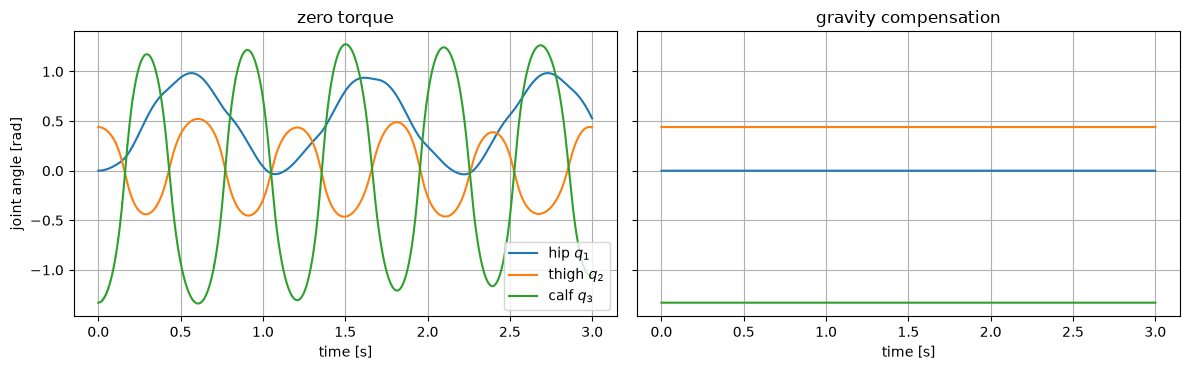

gravity compensation: max |q(t) - q0| = 1.74e-14 rad


In [9]:
q0 = np.array([0.0, 0.44, -1.33])
DURATION = 3.0

runs = {}
runs["zero torque"] = LegSimulation(URDF_PATH, q0).run(lambda t, q, v: np.zeros(3), DURATION)
runs["gravity compensation"] = LegSimulation(URDF_PATH, q0).run(
    lambda t, q, v: pin.computeGeneralizedGravity(model, data, q), DURATION)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (name, (T, Q, V, U)) in zip(axes, runs.items()):
    for j, lab in enumerate(["hip $q_1$", "thigh $q_2$", "calf $q_3$"]):
        ax.plot(T, Q[:, j], label=lab)
    ax.set_title(name); ax.set_xlabel("time [s]"); ax.grid(True)
axes[0].set_ylabel("joint angle [rad]"); axes[0].legend()
fig.tight_layout(); plt.show()

Q_gc = runs["gravity compensation"][1]
print(f"gravity compensation: max |q(t) - q0| = {np.abs(Q_gc - q0).max():.2e} rad")

### 7.2 Position control: PD vs. PD + gravity compensation

$$
\text{PD:}\quad \boldsymbol\tau = \mathbf K_p(\mathbf q_d - \mathbf q) - \mathbf K_d\dot{\mathbf q}
\qquad\qquad
\text{PD+G:}\quad \boldsymbol\tau = \mathbf K_p(\mathbf q_d - \mathbf q) - \mathbf K_d\dot{\mathbf q} + \mathbf G(\mathbf q)
$$

At steady state ($\dot{\mathbf q} = 0$) the plain PD law balances gravity only through a position error, $\mathbf q_d - \mathbf q = \mathbf K_p^{-1}\mathbf G(\mathbf q)$. Lower gains therefore give larger errors. Adding $\mathbf G(\mathbf q)$ removes this error in theory, for any gains.

PD                   steady-state error [rad]: [-0.0197  0.0249 -0.0182]
PD + gravity comp.   steady-state error [rad]: [ 0. -0.  0.]


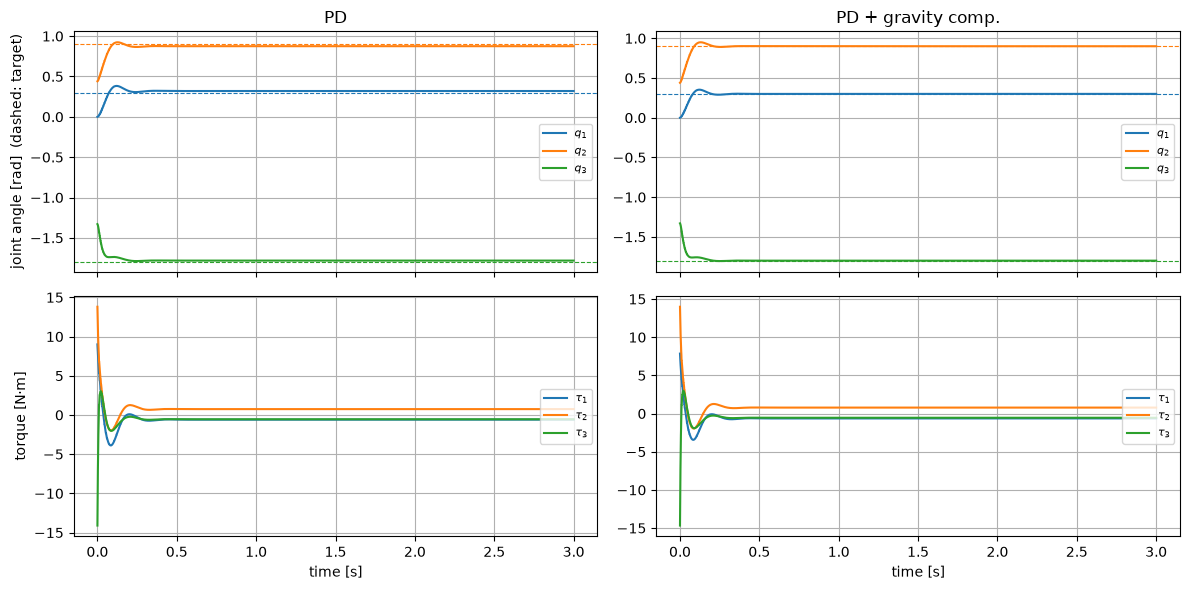

predicted PD error  K_p^-1 G(q): [-0.0197  0.0249 -0.0182]


In [10]:
q_target = np.array([0.3, 0.9, -1.8])
KP, KD = 30.0, 1.0

def pd(t, q, v):
    return KP * (q_target - q) - KD * v

def pd_g(t, q, v):
    return pd(t, q, v) + pin.computeGeneralizedGravity(model, data, q)

ctrl_runs = {"PD": LegSimulation(URDF_PATH, q0).run(pd, DURATION),
             "PD + gravity comp.": LegSimulation(URDF_PATH, q0).run(pd_g, DURATION)}

fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for col, (name, (T, Q, V, U)) in enumerate(ctrl_runs.items()):
    for j, lab in enumerate(["$q_1$", "$q_2$", "$q_3$"]):
        line, = axes[0, col].plot(T, Q[:, j], label=lab)
        axes[0, col].axhline(q_target[j], ls="--", color=line.get_color(), lw=0.8)
        axes[1, col].plot(T, U[:, j], label=rf"$\tau_{j+1}$")
    axes[0, col].set_title(name)
    axes[1, col].set_xlabel("time [s]")
    ss_err = q_target - Q[-1]
    print(f"{name:20s} steady-state error [rad]: {ss_err.round(4)}")
axes[0, 0].set_ylabel("joint angle [rad]  (dashed: target)"); axes[1, 0].set_ylabel("torque [N·m]")
for ax in axes.flat:
    ax.grid(True); ax.legend(loc="right", fontsize=8)
fig.tight_layout(); plt.show()

# Predicted steady-state error of the plain PD law: K_p^{-1} G(q_final)
q_final_pd = ctrl_runs["PD"][1][-1]
print("predicted PD error  K_p^-1 G(q):", (pin.computeGeneralizedGravity(model, data, q_final_pd) / KP).round(4))

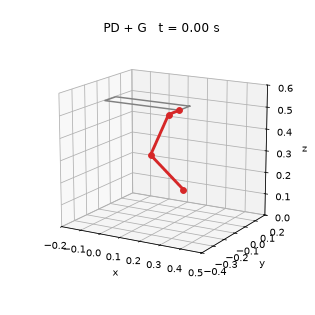

In [11]:
# Animation of the PD + gravity-compensation run, saved for the README
T, Q, _, _ = ctrl_runs["PD + gravity comp."]
frames = np.arange(0, len(T), 25)
fig = plt.figure(figsize=(4.5, 4.5))
ax = fig.add_subplot(projection="3d")
ax.plot(corners[:, 0], corners[:, 1], 0.5, color="gray")
line, = ax.plot([], [], [], "o-", lw=3, color="tab:red")
trail, = ax.plot([], [], [], "-", lw=1, color="tab:blue", alpha=0.5)
foot = np.array([forward_kinematics(q) for q in Q])
ax.set_xlim(-0.2, 0.5); ax.set_ylim(-0.4, 0.2); ax.set_zlim(0.0, 0.6)
ax.set_box_aspect((0.7, 0.6, 0.6)); ax.view_init(elev=15, azim=-60)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
title = ax.set_title("")

def update(n):
    i = frames[n]
    P = joint_positions(Q[i])
    line.set_data_3d(P[1:, 0], P[1:, 1], P[1:, 2])
    trail.set_data_3d(foot[:i + 1, 0], foot[:i + 1, 1], foot[:i + 1, 2])
    title.set_text(f"PD + G   t = {T[i]:.2f} s")
    return line, trail, title

anim = FuncAnimation(fig, update, frames=len(frames))
anim.save(MEDIA / "leg_pd_gravity.gif", writer=PillowWriter(fps=20), dpi=70)
plt.close(fig)
Image(filename=str(MEDIA / "leg_pd_gravity.gif"))

## 8. Discussion

- **Kinematics.** The closed-form foot position agrees with Pinocchio to machine precision over 1000 random configurations, including large angles. The Jacobian passes both the velocity check and a finite-difference check that is independent of Pinocchio.
- **Dynamics.** The hand-derived Euler–Lagrange model of the thigh–calf chain gives the same $\mathbf M$, $\mathbf C$ and $\mathbf G$ as Pinocchio's CRBA / RNEA. This confirms both the derivation and the inertial parameters in the URDF.
- **Gravity compensation.** Drake and Pinocchio use the same model, so $\boldsymbol\tau = \mathbf G(\mathbf q)$ exactly cancels gravity and the leg stays at rest. With zero torque the leg falls and swings, as expected for an unactuated pendulum-like chain.
- **PD vs. PD+G.** Plain PD control leaves a steady-state error equal to $\mathbf K_p^{-1}\mathbf G(\mathbf q)$, which the simulation reproduces. Adding gravity compensation removes it. Very large targets can also be blocked by self-collision or the joint limits in the URDF, so a large final error is not always a gain-tuning problem.
- **Limitations.** The model uses primitive geometry with rough masses and inertias, has no joint friction, motor dynamics or torque limits in the controller, and keeps the body fixed. A real quadruped has a floating base and contact forces at the feet.